In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [31]:
sns.set_theme(style="whitegrid")

In [32]:
df=pd.read_csv('Dataset.csv')

In [33]:
df['sales'] = pd.to_numeric(df['sales'].astype(str).str.replace(',', ''), errors='coerce')
df['profit'] = pd.to_numeric(df['profit'], errors='coerce')

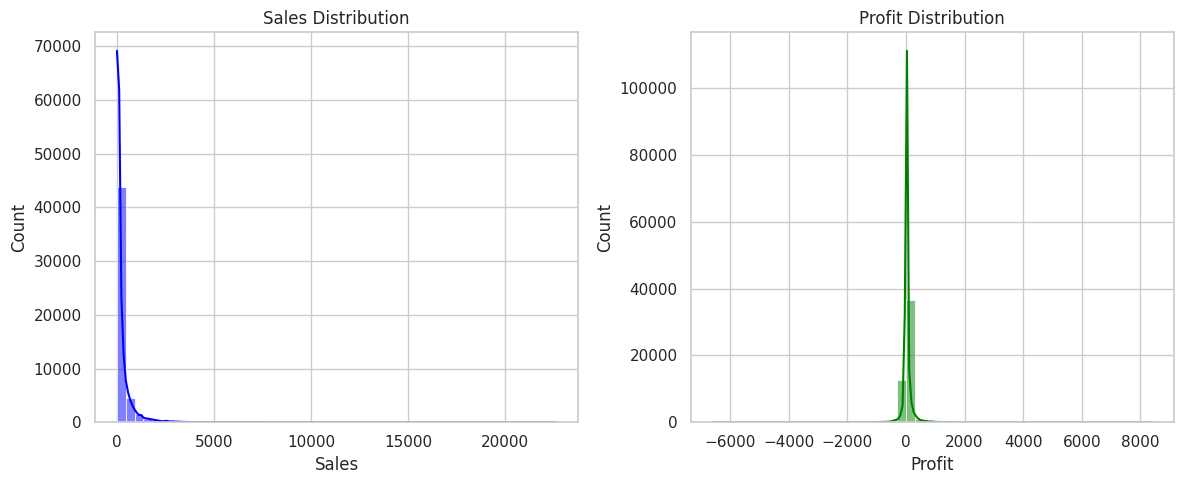

In [34]:
plt.figure(figsize=(12, 5))

# Sales Distribution
plt.subplot(1, 2, 1)
sns.histplot(df['sales'].dropna(), bins=50, kde=True, color='blue')
plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Count')

# Profit Distribution
plt.subplot(1, 2, 2)
sns.histplot(df['profit'].dropna(), bins=50, kde=True, color='green')
plt.title('Profit Distribution')
plt.xlabel('Profit')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

<Figure size 1400x600 with 0 Axes>

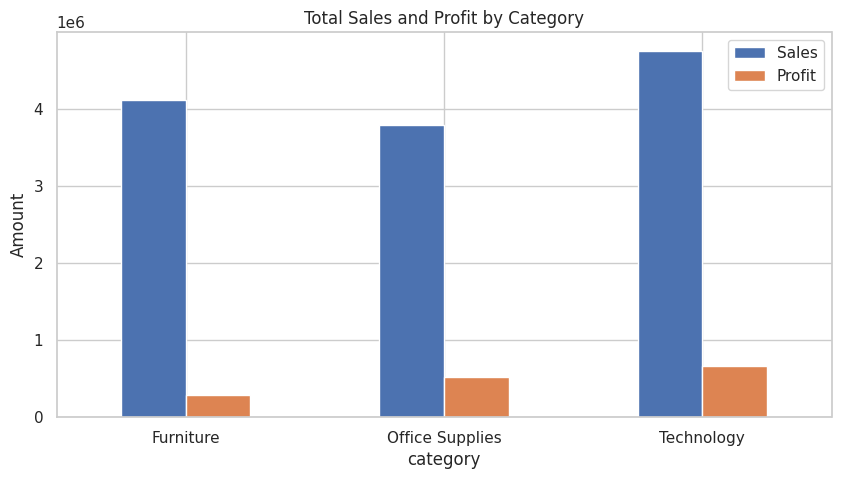

In [35]:
plt.figure(figsize=(14, 6))

# Category wise Sales & Profit
cat_perf = df.groupby('category')[['sales', 'profit']].sum().reset_index()

cat_perf.plot(x='category', y=['sales', 'profit'], kind='bar', figsize=(10, 5))
plt.title('Total Sales and Profit by Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend(['Sales', 'Profit'])
plt.show()

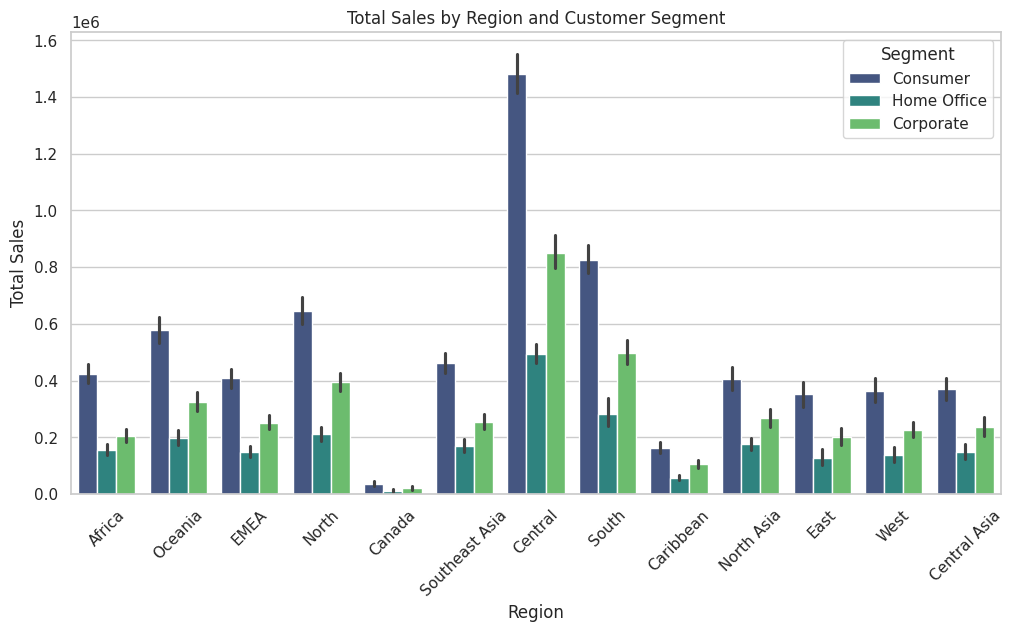

In [36]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='region', y='sales', hue='segment', estimator=np.sum, palette='viridis')
plt.title('Total Sales by Region and Customer Segment')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend(title='Segment')
plt.show()

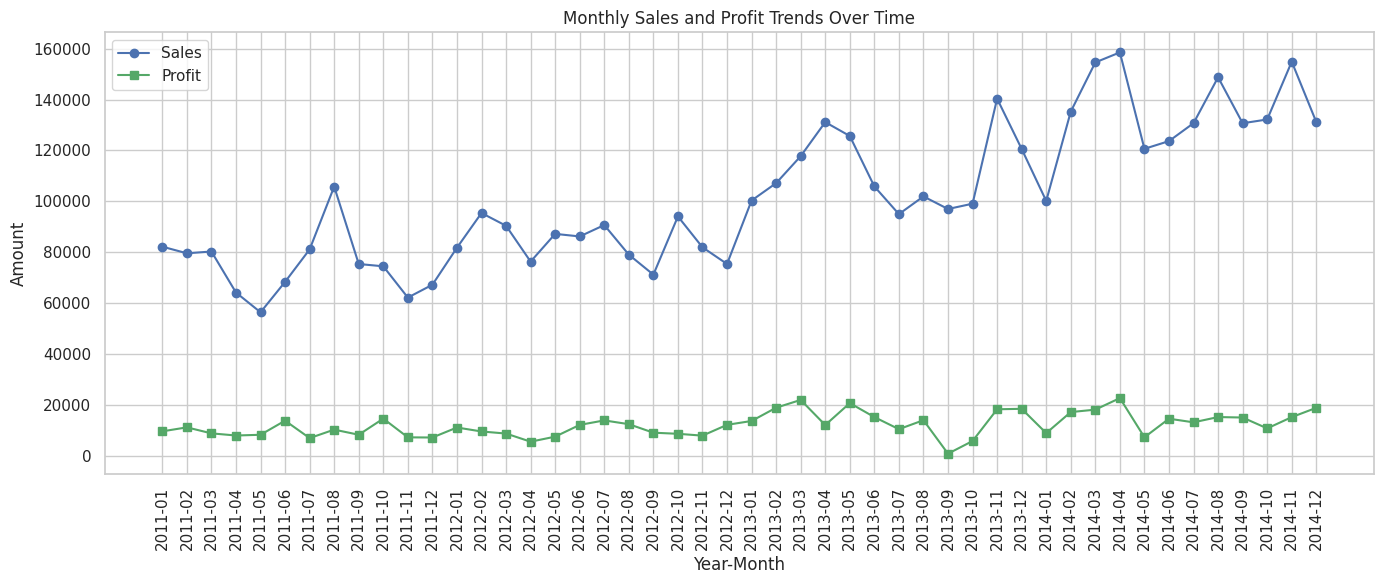

In [37]:
# Order Date convert to datetime format
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['year_month'] = df['order_date'].dt.to_period('M')

# Monthly aggregation
monthly_trend = df.groupby('year_month')[['sales', 'profit']].sum().reset_index()
monthly_trend['year_month'] = monthly_trend['year_month'].astype(str)

plt.figure(figsize=(14, 6))
plt.plot(monthly_trend['year_month'], monthly_trend['sales'], label='Sales', marker='o', color='b')
plt.plot(monthly_trend['year_month'], monthly_trend['profit'], label='Profit', marker='s', color='g')
plt.title('Monthly Sales and Profit Trends Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Amount')
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

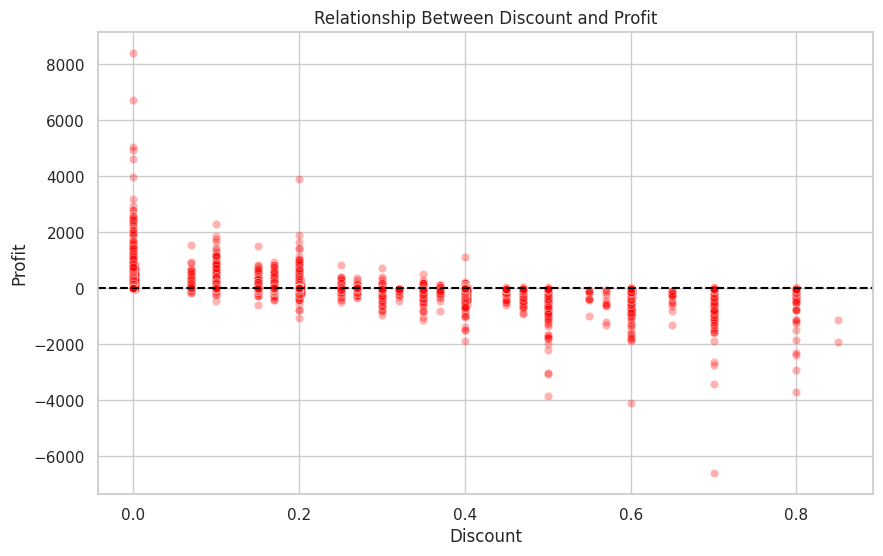

In [38]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='discount', y='profit', alpha=0.3, color='red')
plt.title('Relationship Between Discount and Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.axhline(0, color='black', linestyle='--') # 0 profit line
plt.show()